In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

In [4]:
# Load diabetes dataset
df = pd.read_csv(r"C:\Users\hp\Downloads\diabetes.csv")

print("Dataset Loaded Successfully")

df.head()

Dataset Loaded Successfully


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
# Display first five rows
print(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Dataset shape
print("\nDataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical description
print("\nStatistical Summary:")
print(df.describe())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insu

In [6]:
# Replace invalid zero values with median
columns = ['Glucose', 'BloodPressure',
           'SkinThickness', 'Insulin', 'BMI']

for col in columns:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

# Check missing values
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

Missing Values After Cleaning:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Dataset Shape: (768, 9)


In [7]:
X = df.drop('Outcome', axis=1)

y = df['Outcome']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0    125.0  33.6   
1            1     85.0           66.0           29.0    125.0  26.6   
2            8    183.0           64.0           29.0    125.0  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   Pedigree  Age  
0     0.627   50  
1     0.351   31  
2     0.672   32  
3     0.167   21  
4     2.288   33  

Target:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


In [9]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [10]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

print("KNN Model Trained Successfully")

KNN Model Trained Successfully


In [11]:
# Predict test data
y_pred = knn.predict(X_test)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test.values)

Predicted Values:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 1 0 0
 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 0 1 1 1
 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 0 0 0 0 1 0
 0 0 0 0 1 0]

Actual Values:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 1 0
 0 1 0 0 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 1 0 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0
 1 1 1 1 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1
 0 0 0 0 1 0]


Confusion Matrix:
[[83 17]
 [21 33]]


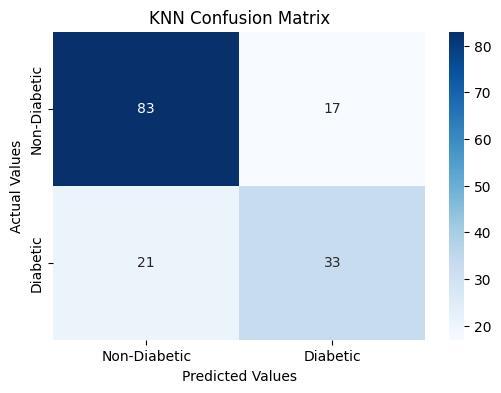

In [12]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("KNN Confusion Matrix")

plt.show()

In [13]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

error_rate = 1 - accuracy

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

print("KNN Model Performance")

print("Accuracy:", accuracy)
print("Error Rate:", error_rate)
print("Precision:", precision)
print("Recall:", recall)

KNN Model Performance
Accuracy: 0.7532467532467533
Error Rate: 0.24675324675324672
Precision: 0.66
Recall: 0.6111111111111112


In [14]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



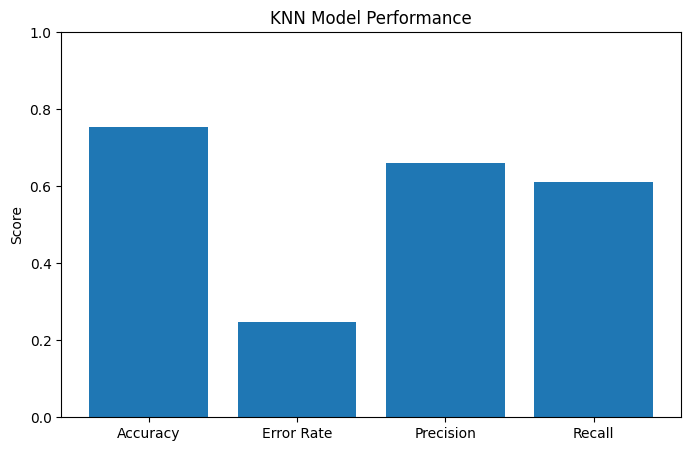

In [15]:
metrics = {
    'Accuracy': accuracy,
    'Error Rate': error_rate,
    'Precision': precision,
    'Recall': recall
}

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.title("KNN Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.show()